In [2]:
import sys
sys.path.append("/hlabhome/wg-mjames/git/Toby_work")
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
from collections import Counter
from threadpoolctl import threadpool_info, threadpool_limits
%load_ext autoreload
%autoreload 2
import os
NCPU = "4"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
split_thres = (0.4, 0.6)
addon='unfiltered'
#early_train_exit specifies that you just want the train/test distribution, without added scaled features of the distribution,
#which isn't necessary for MLP stuff since it is trained directly on the distribution itself.
train, test= generate_train_test_dataset(split_thres, addon, early_train_exit=True)

Loading Dataset
adding column if necessary
Filtering out lame neurons
Splitting into train/test 500 isi chunks


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [00:55<00:00, 77.25it/s]


Add in some ids
minimizing stuff in the train dataset
Not filtering the dataset/downsampling isis, assuming this is intentional!


In [4]:
train_condensed = get_extended_condensed_data(train)
sw_train = get_sleep_state_conversion(train)
sw_test = get_sleep_state_conversion(test)
sw_train_condensed = get_extended_condensed_data(sw_train)
train = sw_train
test = sw_test

In [4]:
start_val,stop_val,bin_size = 0.0015,3,0.01 #in seconds
isi_bins = np.arange(start_val,stop_val,bin_size)
N_BINS = 100
BIN_EDGES = np.logspace(np.log10(0.001), np.log10(60), N_BINS + 1)
def obtain_distribution(unit_isi, log_spaced=True):
    if not log_spaced:
        unit_isi_distrib, _ = np.histogram(unit_isi, isi_bins, density=False)
    else: unit_isi_distrib, _ = np.histogram(unit_isi, BIN_EDGES)
    
    if unit_isi_distrib.sum()!=0: #min max normalization
        unit_isi_distrib = (unit_isi_distrib-np.min(unit_isi_distrib))/(np.max(unit_isi_distrib)-np.min(unit_isi_distrib))
    
    return unit_isi_distrib
    
tqdm.pandas()
train['isi_distrib'] = train[f'isi'].progress_apply(obtain_distribution)
test['isi_distrib'] = test[f'isi'].progress_apply(obtain_distribution)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 502898/502898 [00:19<00:00, 25768.94it/s]


In [5]:
#Remove any nans (though there shouldn't be any)
arrs = [train, test]
for i in range(len(arrs)):
    arrs[i]['nan_m'] = arrs[i].isi_distrib.progress_apply(lambda x: np.any(np.isnan(x)))
    arrs[i] = arrs[i][~arrs[i].nan_m]
    arrs[i] = arrs[i].drop(columns='nan_m')
    arrs[i] = arrs[i].reset_index(drop=True)
train, test = arrs

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 502898/502898 [00:01<00:00, 251896.90it/s]


In [6]:
#Run the actual per-cell training, saving two backups of the cms in mlp_cms in backup_baseline and baseline.pkl,
# since it takes so long. Makes it resilient to stops+starts. Once complete, copy the cms into a new descriptive folder
#If cms are already in the baseline/backup files, delete them once you have ensured they are saved in a different file
cms = load_safe()
i = 0
print(f"Loaded {len(cms)} confusion matrices from storage")
for cell in tqdm(train.cell.unique()):
    if cell not in cms:
        i+=1
        #before = time.time()
        item = mlp_individual(cell, train, sampling_type='under', num_states=2)
#         if not len(item):
#             print("SMOTE must have failed, just do oversampling instead, proceed")
#             item = mlp_individual(cell, train, sampling_type='over')
        if not len(item):
            print("Skip this chump")
            continue
        #after = time.time()
        #print(f"This model took |{after-before} to train, had {item['training_length']} to go through")
        if item['model'].interrupted:
            print("Oh training got interrupted, exit!!!")
            save_safe(cms)
            break
        cm = get_individual_cm(item, test, get_spiking=True, use_spike_matrix=False)
        if not len(cm):
            print("This cm failed somehow, bypassing")
            continue
        cms[cell] = cm[cell]
        if not i%5:
            save_safe(cms)

Initial load failed-> Ran out of input
Trying backup
secondary worked alright
Loaded 1529 confusion matrices from storage


 43%|███████████████████████████████████████████████▋                                                                | 1837/4317 [12:46<33:58,  1.22it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 43%|████████████████████████████████████████████████▍                                                               | 1866/4317 [13:40<55:03,  1.35s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 55%|█████████████████████████████████████████████████████████████▌                                                  | 2373/4317 [38:20<56:28,  1.74s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 55%|██

 63%|██████████████████████████████████████████████████████████████████████▉                                         | 2733/4317 [48:01<16:42,  1.58it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 65%|███████████████████████████████████████████████████████████████████████                                       | 2788/4317 [49:40<1:07:34,  2.65s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 65%|███████████████████████████████████████████████████████████████████████                                       | 2789/4317 [49:42<1:01:36,  2.42s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 65%|██

 70%|█████████████████████████████████████████████████████████████████████████████▉                                  | 3004/4317 [54:14<14:11,  1.54it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 70%|█████████████████████████████████████████████████████████████████████████████▉                                  | 3006/4317 [54:14<10:18,  2.12it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 70%|██████████████████████████████████████████████████████████████████████████████                                  | 3007/4317 [54:14<08:22,  2.61it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 70%|██

 70%|██████████████████████████████████████████████████████████████████████████████▊                                 | 3039/4317 [54:33<15:52,  1.34it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 70%|██████████████████████████████████████████████████████████████████████████████▉                                 | 3041/4317 [54:33<09:51,  2.16it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped

 73%|█████████████████████████████████████████████████████████████████████████████████▋                              | 3147/4317 [56:00<11:45,  1.66it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 73%|█████████████████████████████████████████████████████████████████████████████████▋                              | 3148/4317 [56:00<09:23,  2.08it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 73%|█████████████████████████████████████████████████████████████████████████████████▋                              | 3149/4317 [56:02<17:30,  1.11it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 73%|██

 75%|████████████████████████████████████████████████████████████████████████████████████▍                           | 3256/4317 [58:51<16:56,  1.04it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 76%|███████████████████████████████████████████████████████████████████████████████████▏                          | 3266/4317 [59:15<1:00:56,  3.48s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 76%|█████████████████████████████████████████████████████████████████████████████████████                           | 3278/4317 [59:46<22:59,  1.33s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 76%|██

 83%|███████████████████████████████████████████████████████████████████████████████████████████▎                  | 3584/4317 [1:05:48<16:25,  1.34s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 83%|███████████████████████████████████████████████████████████████████████████████████████████▌                  | 3592/4317 [1:05:59<17:09,  1.42s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 83%|███████████████████████████████████████████████████████████████████████████████████████████▋                  | 3600/4317 [1:06:09<16:08,  1.35s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 83%|██

 89%|█████████████████████████████████████████████████████████████████████████████████████████████████▉            | 3842/4317 [1:13:15<04:07,  1.92it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 89%|██████████████████████████████████████████████████████████████████████████████████████████████████            | 3848/4317 [1:13:20<05:50,  1.34it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 89%|██████████████████████████████████████████████████████████████████████████████████████████████████▏           | 3854/4317 [1:13:27<09:08,  1.18s/it]/hlabho

 93%|██████████████████████████████████████████████████████████████████████████████████████████████████████▎       | 4015/4317 [1:17:31<06:42,  1.33s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 93%|██████████████████████████████████████████████████████████████████████████████████████████████████████▎       | 4017/4317 [1:17:31<03:44,  1.34it/s]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 93%|██████████████████████████████████████████████████████████████████████████████████████████████████████▌       | 4024/4317 [1:17:40<06:33,  1.34s/it]/hlabhome/wg-mjames/git/Toby_work/alternateMLPClassifier.py:172: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(
 94%|██

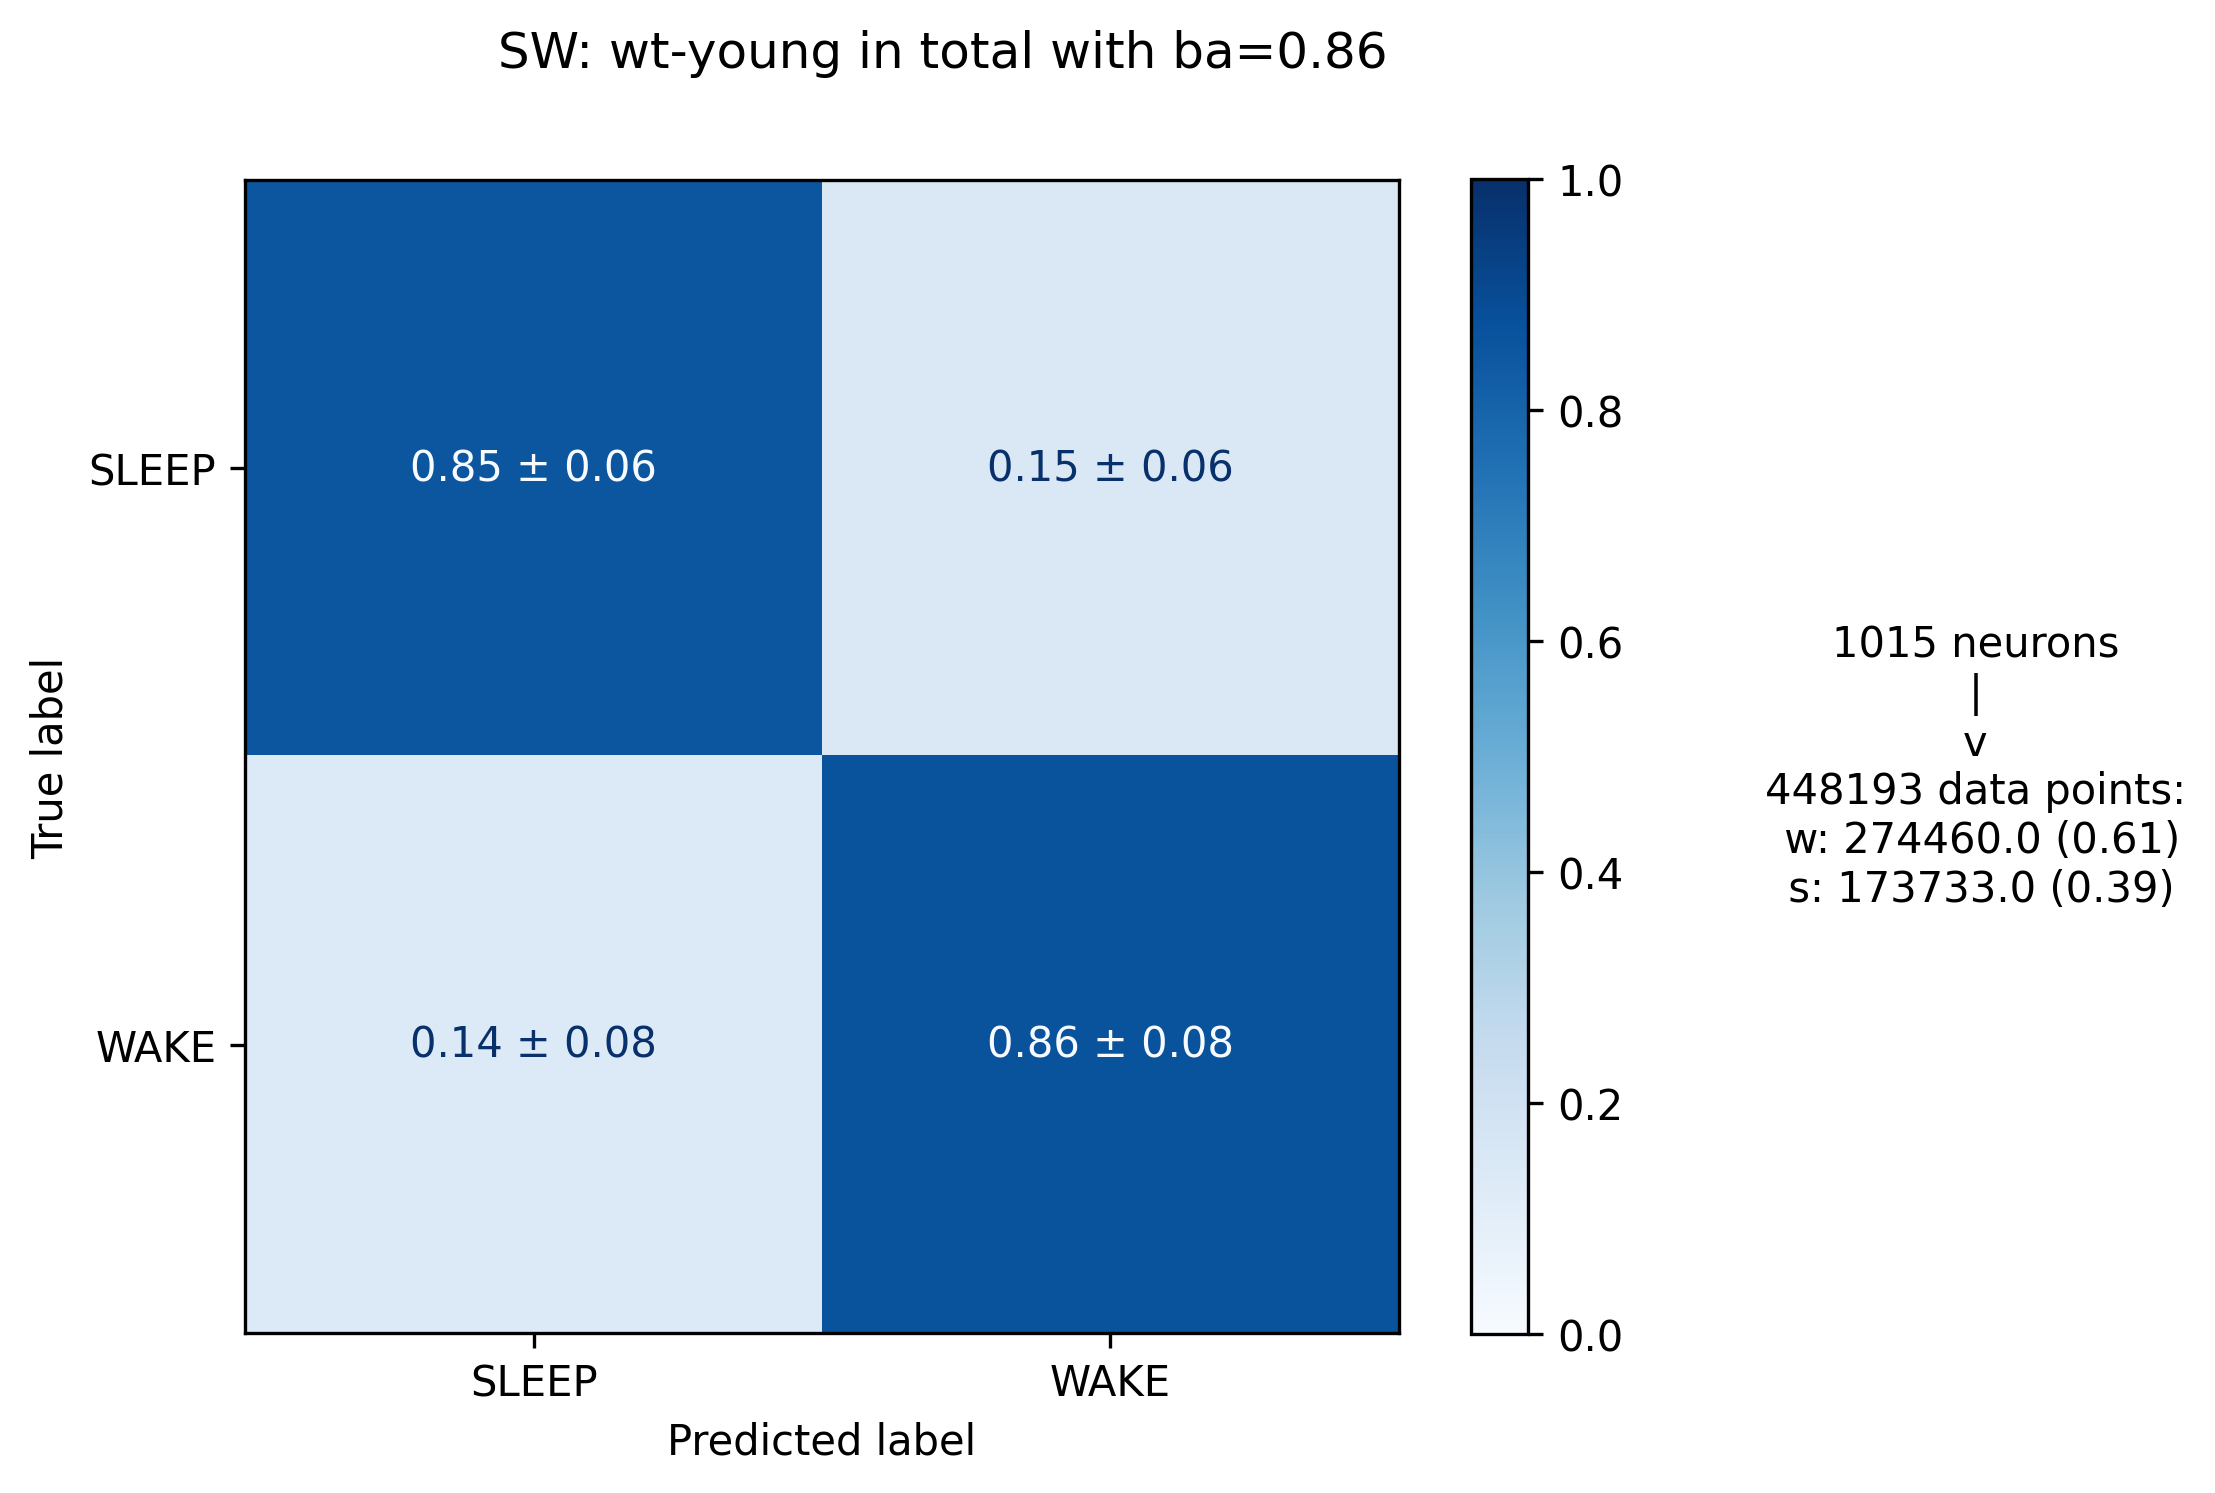

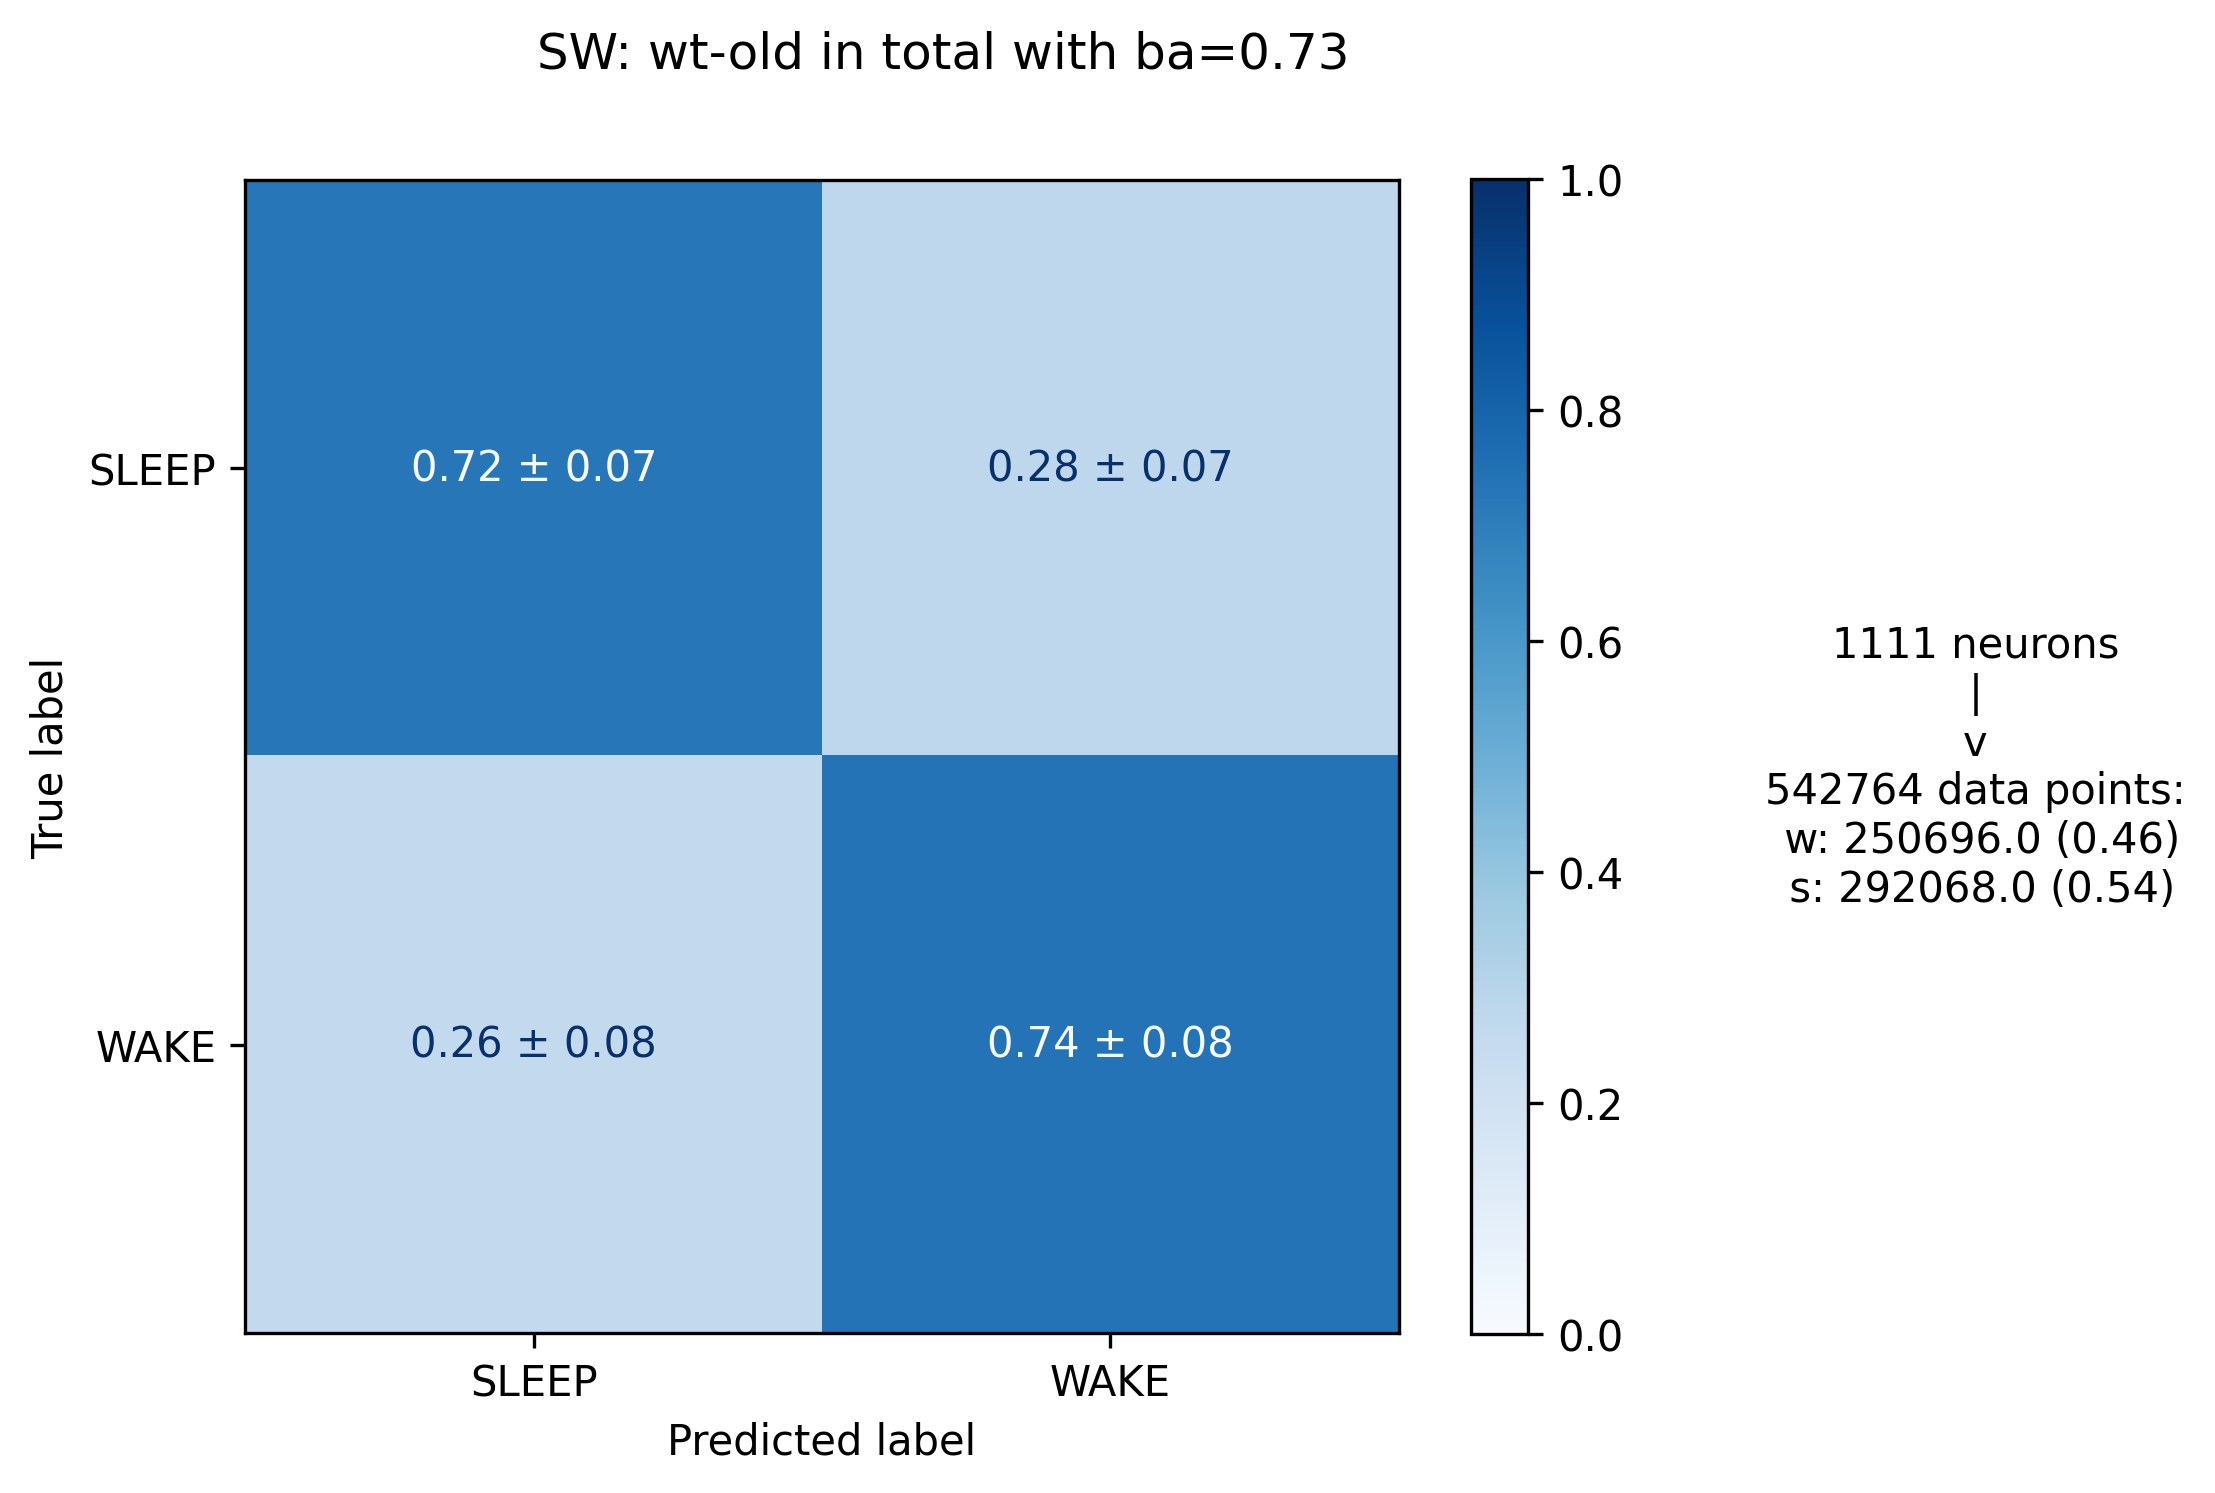

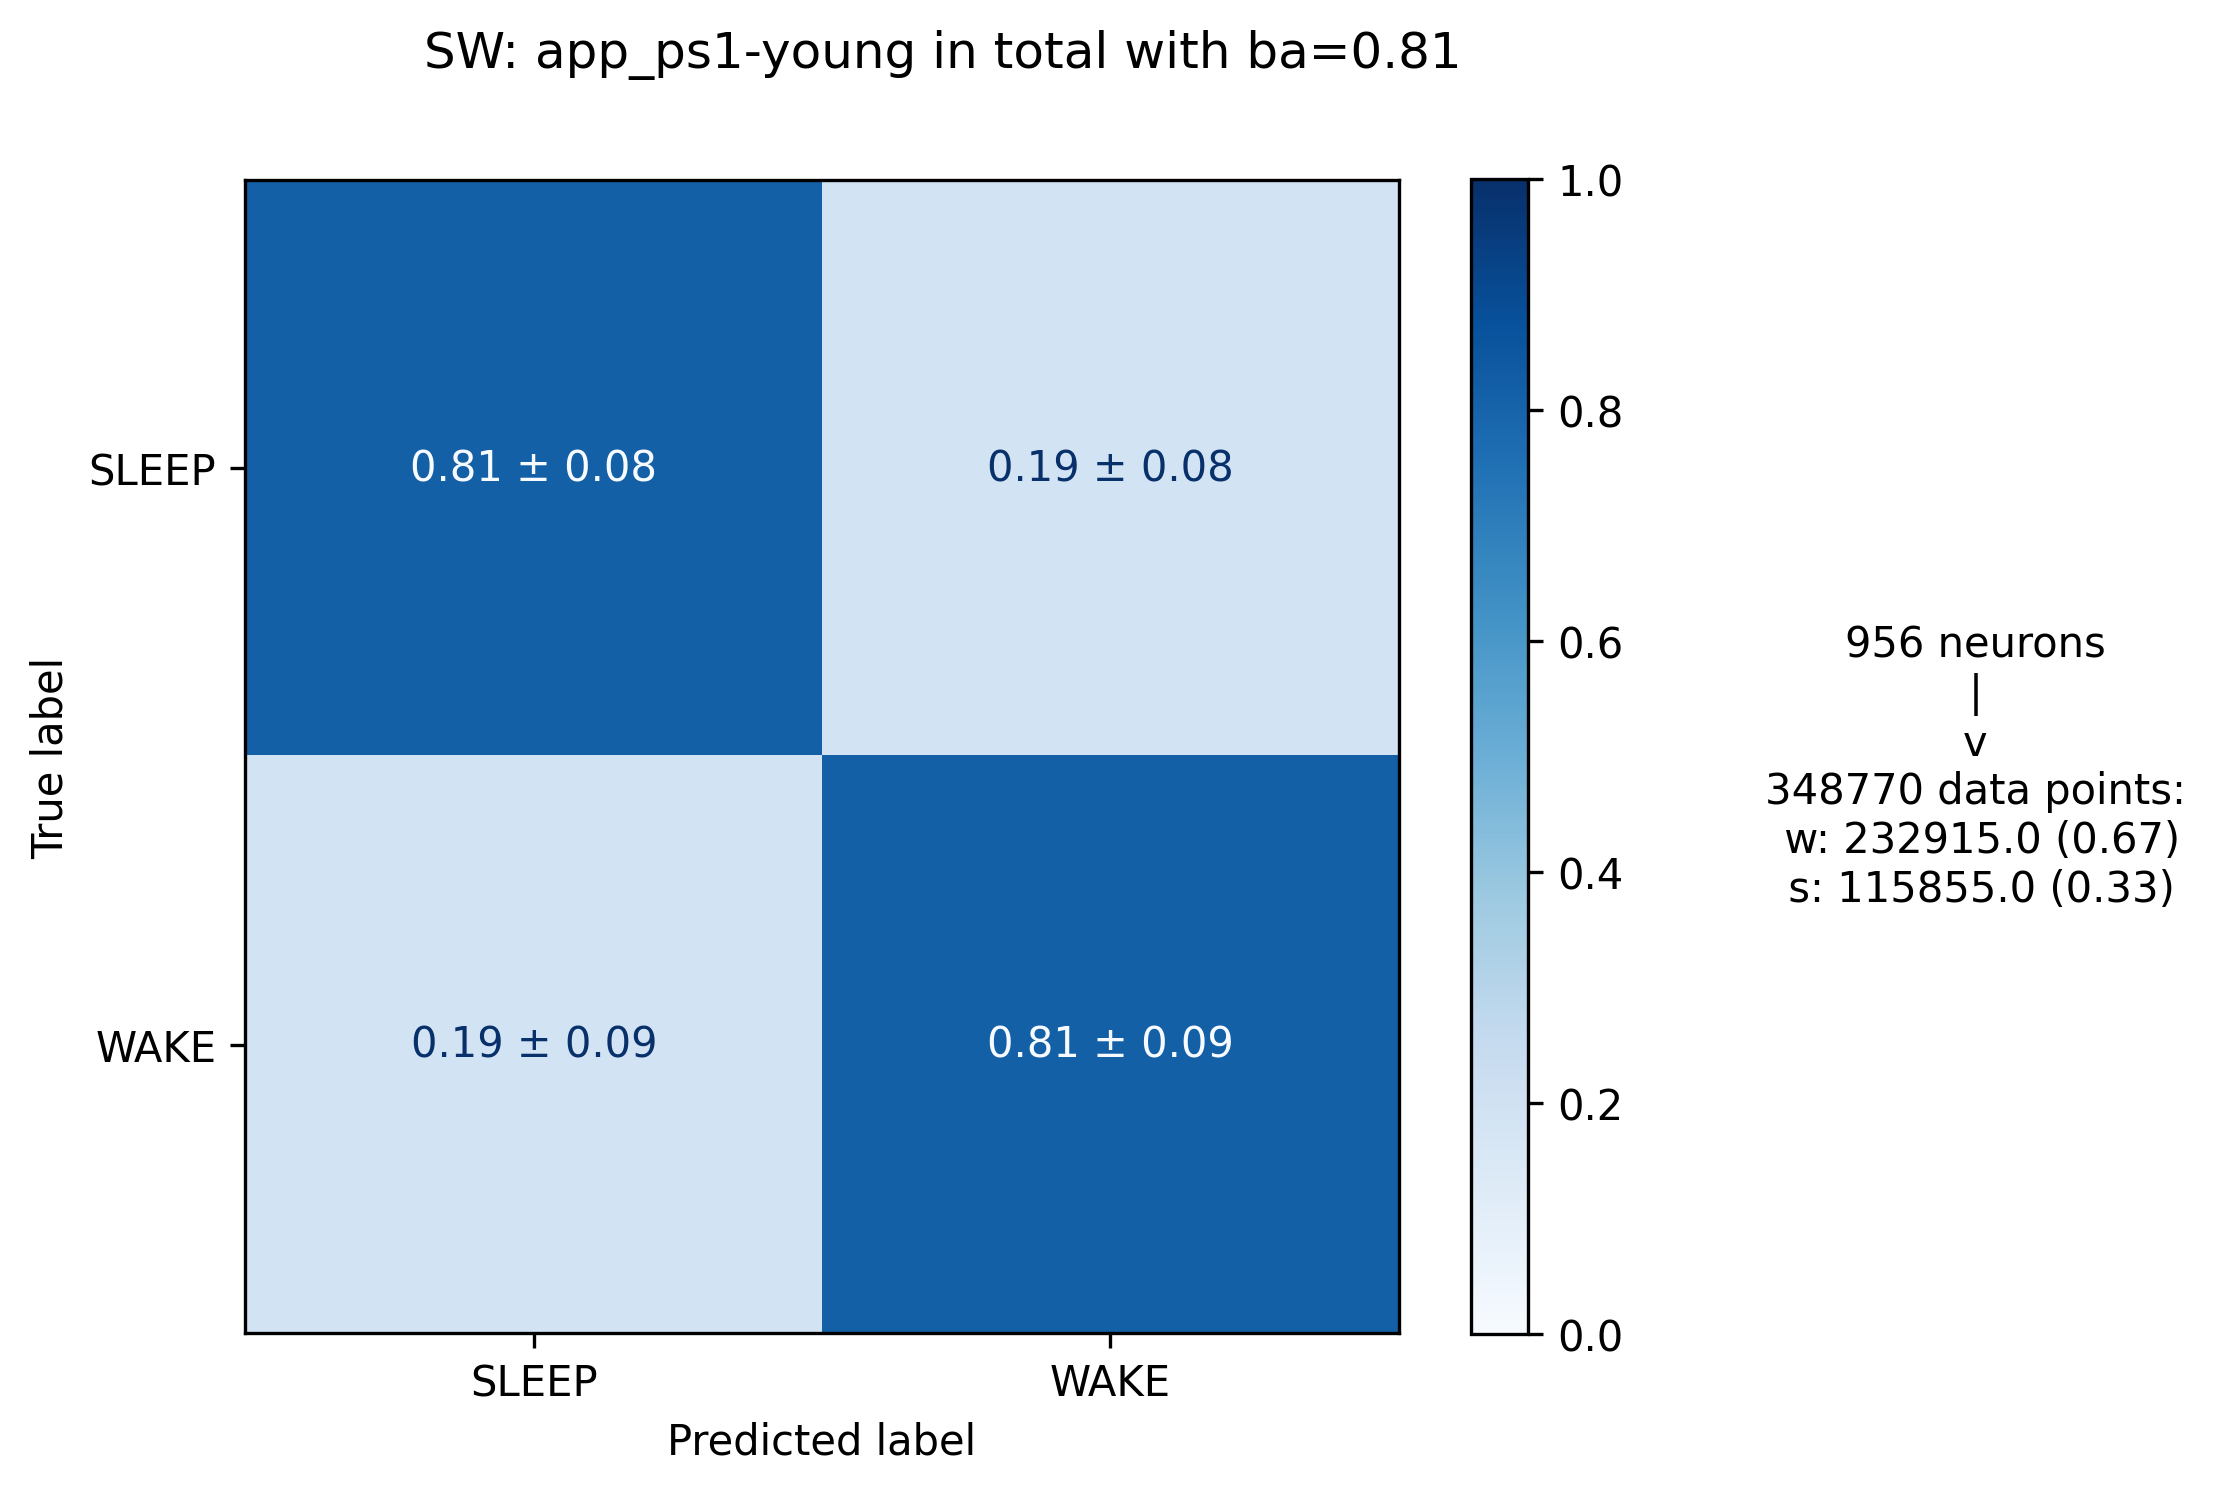

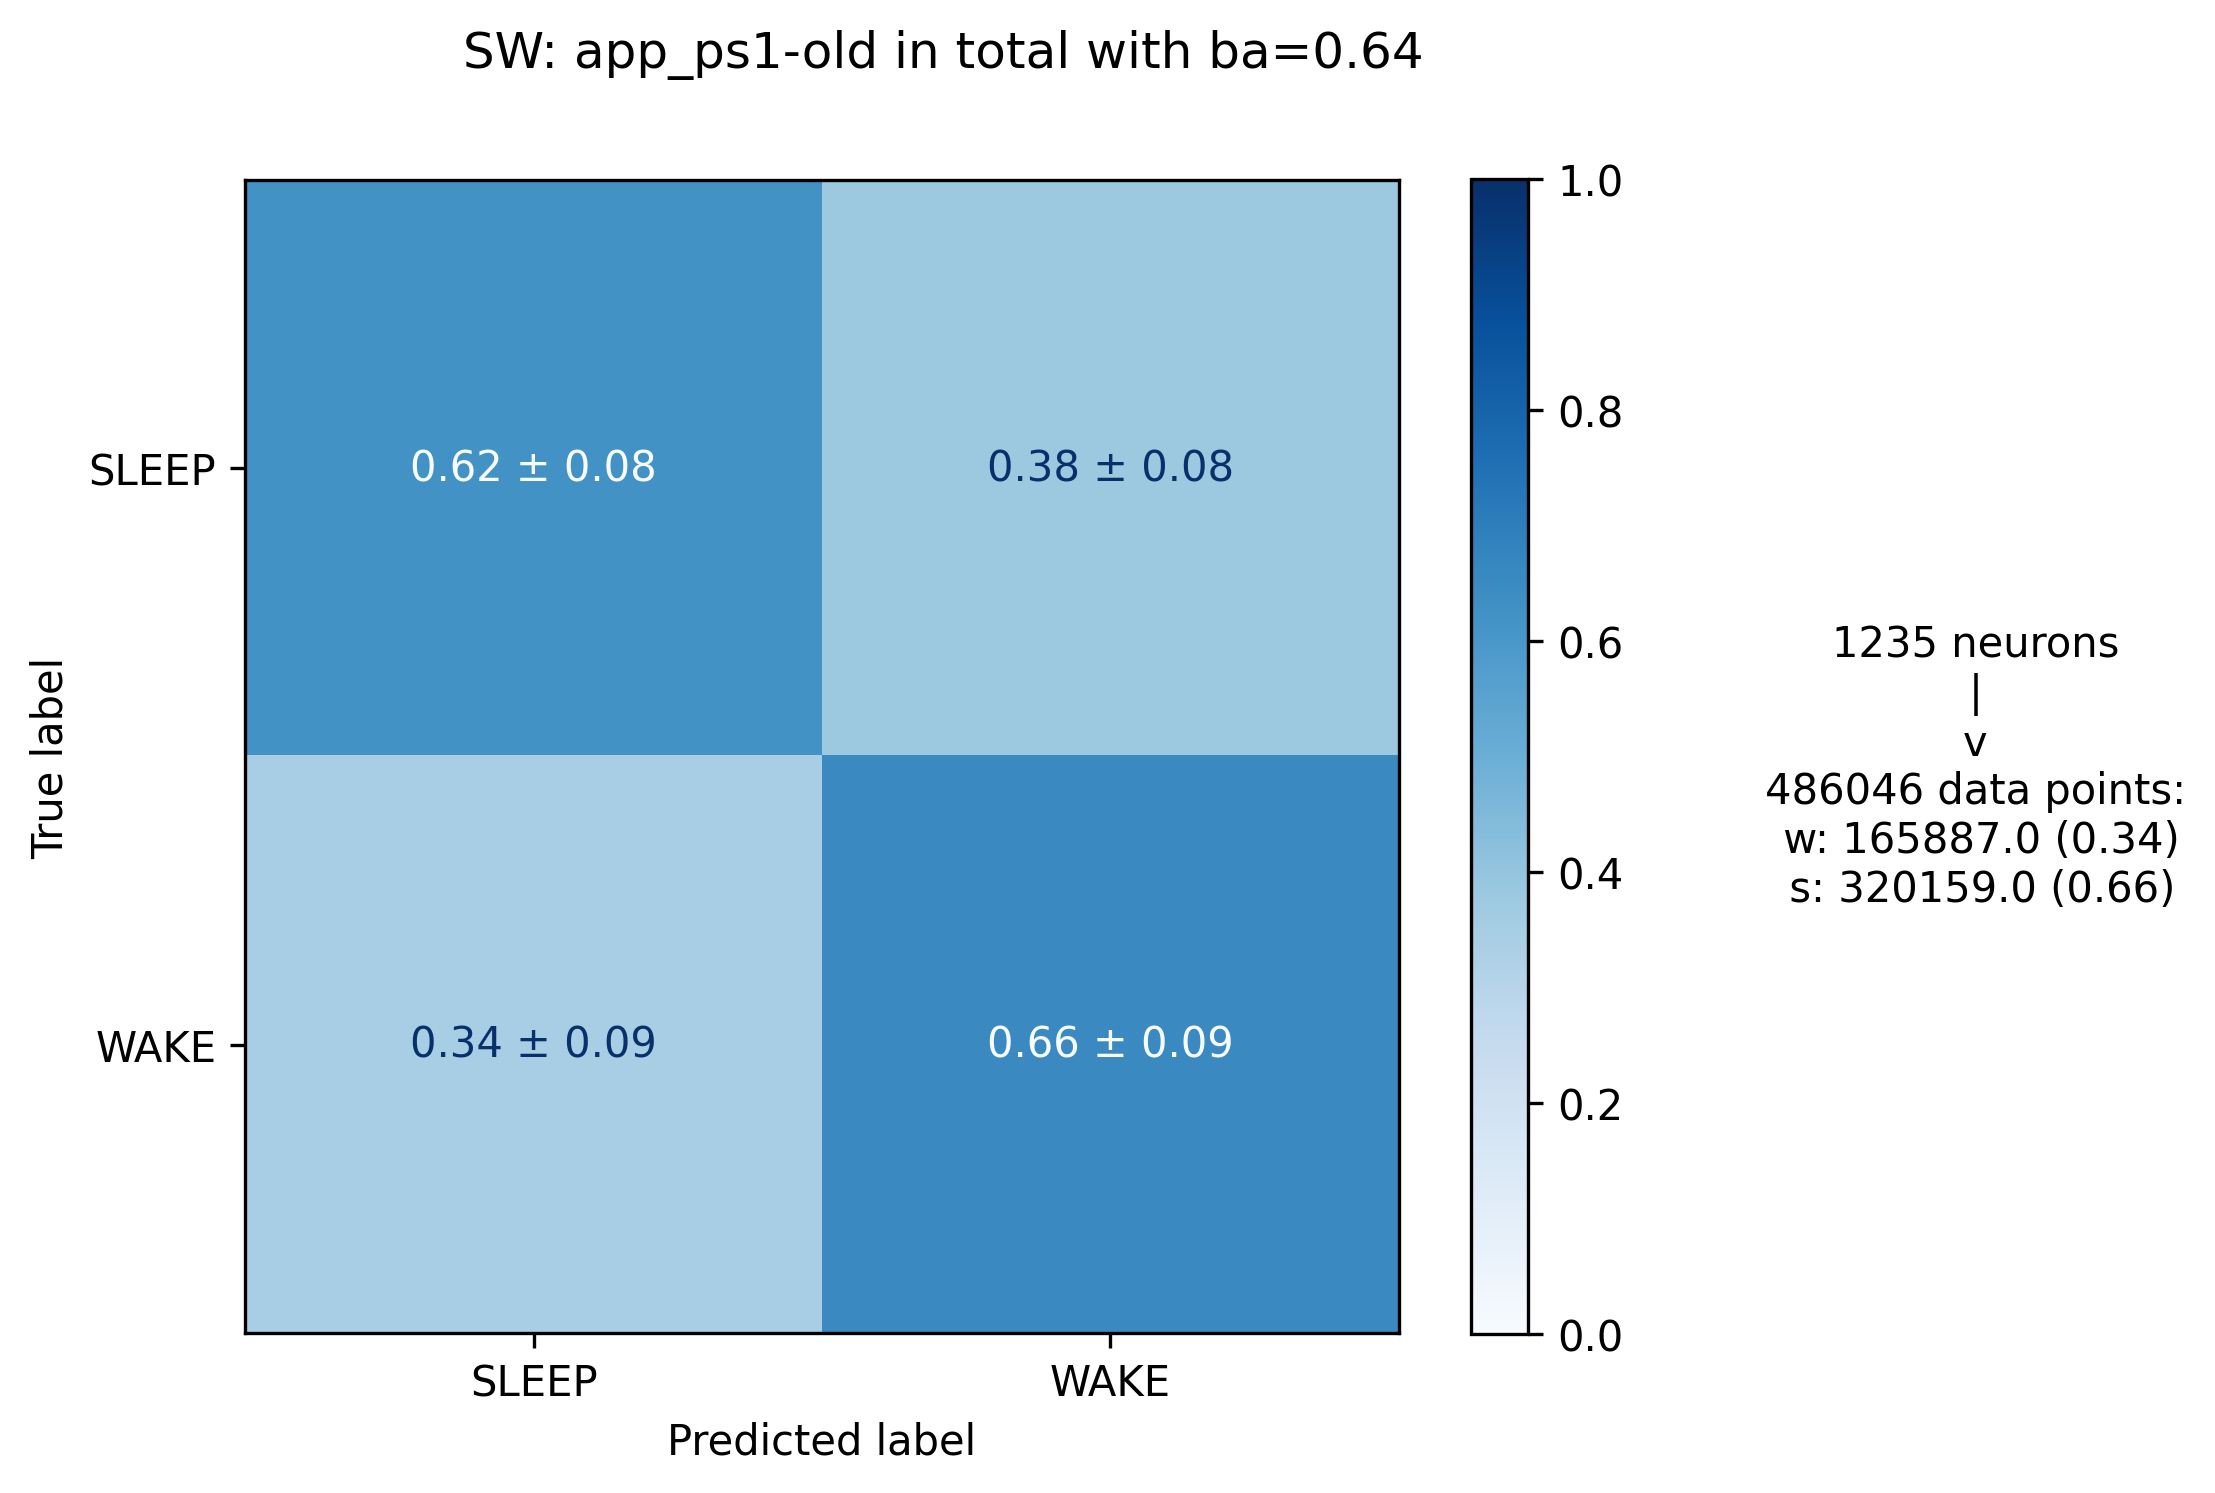

In [5]:

#Specify norm_size=2 so that the visual works for 2 states
get_mean_cms_visual(cms, sw_train_condensed, f"SW", subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                    addon_text=True, alt_se=True, norm_size=2, by_geno=True, by_age=True)

In [3]:
cms = load_safe()

Successfully loaded the main cm dictionary


In [4]:
load_data=True
train_scaled, test_scaled = obtain_train_test_scaled_data((0.4, 0.6), 'unfiltered', True,)

Loaded successfully


In [5]:
sw_train = get_sleep_state_conversion(train_scaled)
sw_test = get_sleep_state_conversion(test_scaled)
sw_train_condensed = get_extended_condensed_data(sw_train)

In [6]:
cms = {'LogRegUnder':cms}

In [10]:
log_models = train_multi_models(sw_train, num_states=2)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [00:34<00:00, 124.49it/s]


In [19]:
log_cms = get_cms_multi(sw_test, log_models)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [00:14<00:00, 298.54it/s]


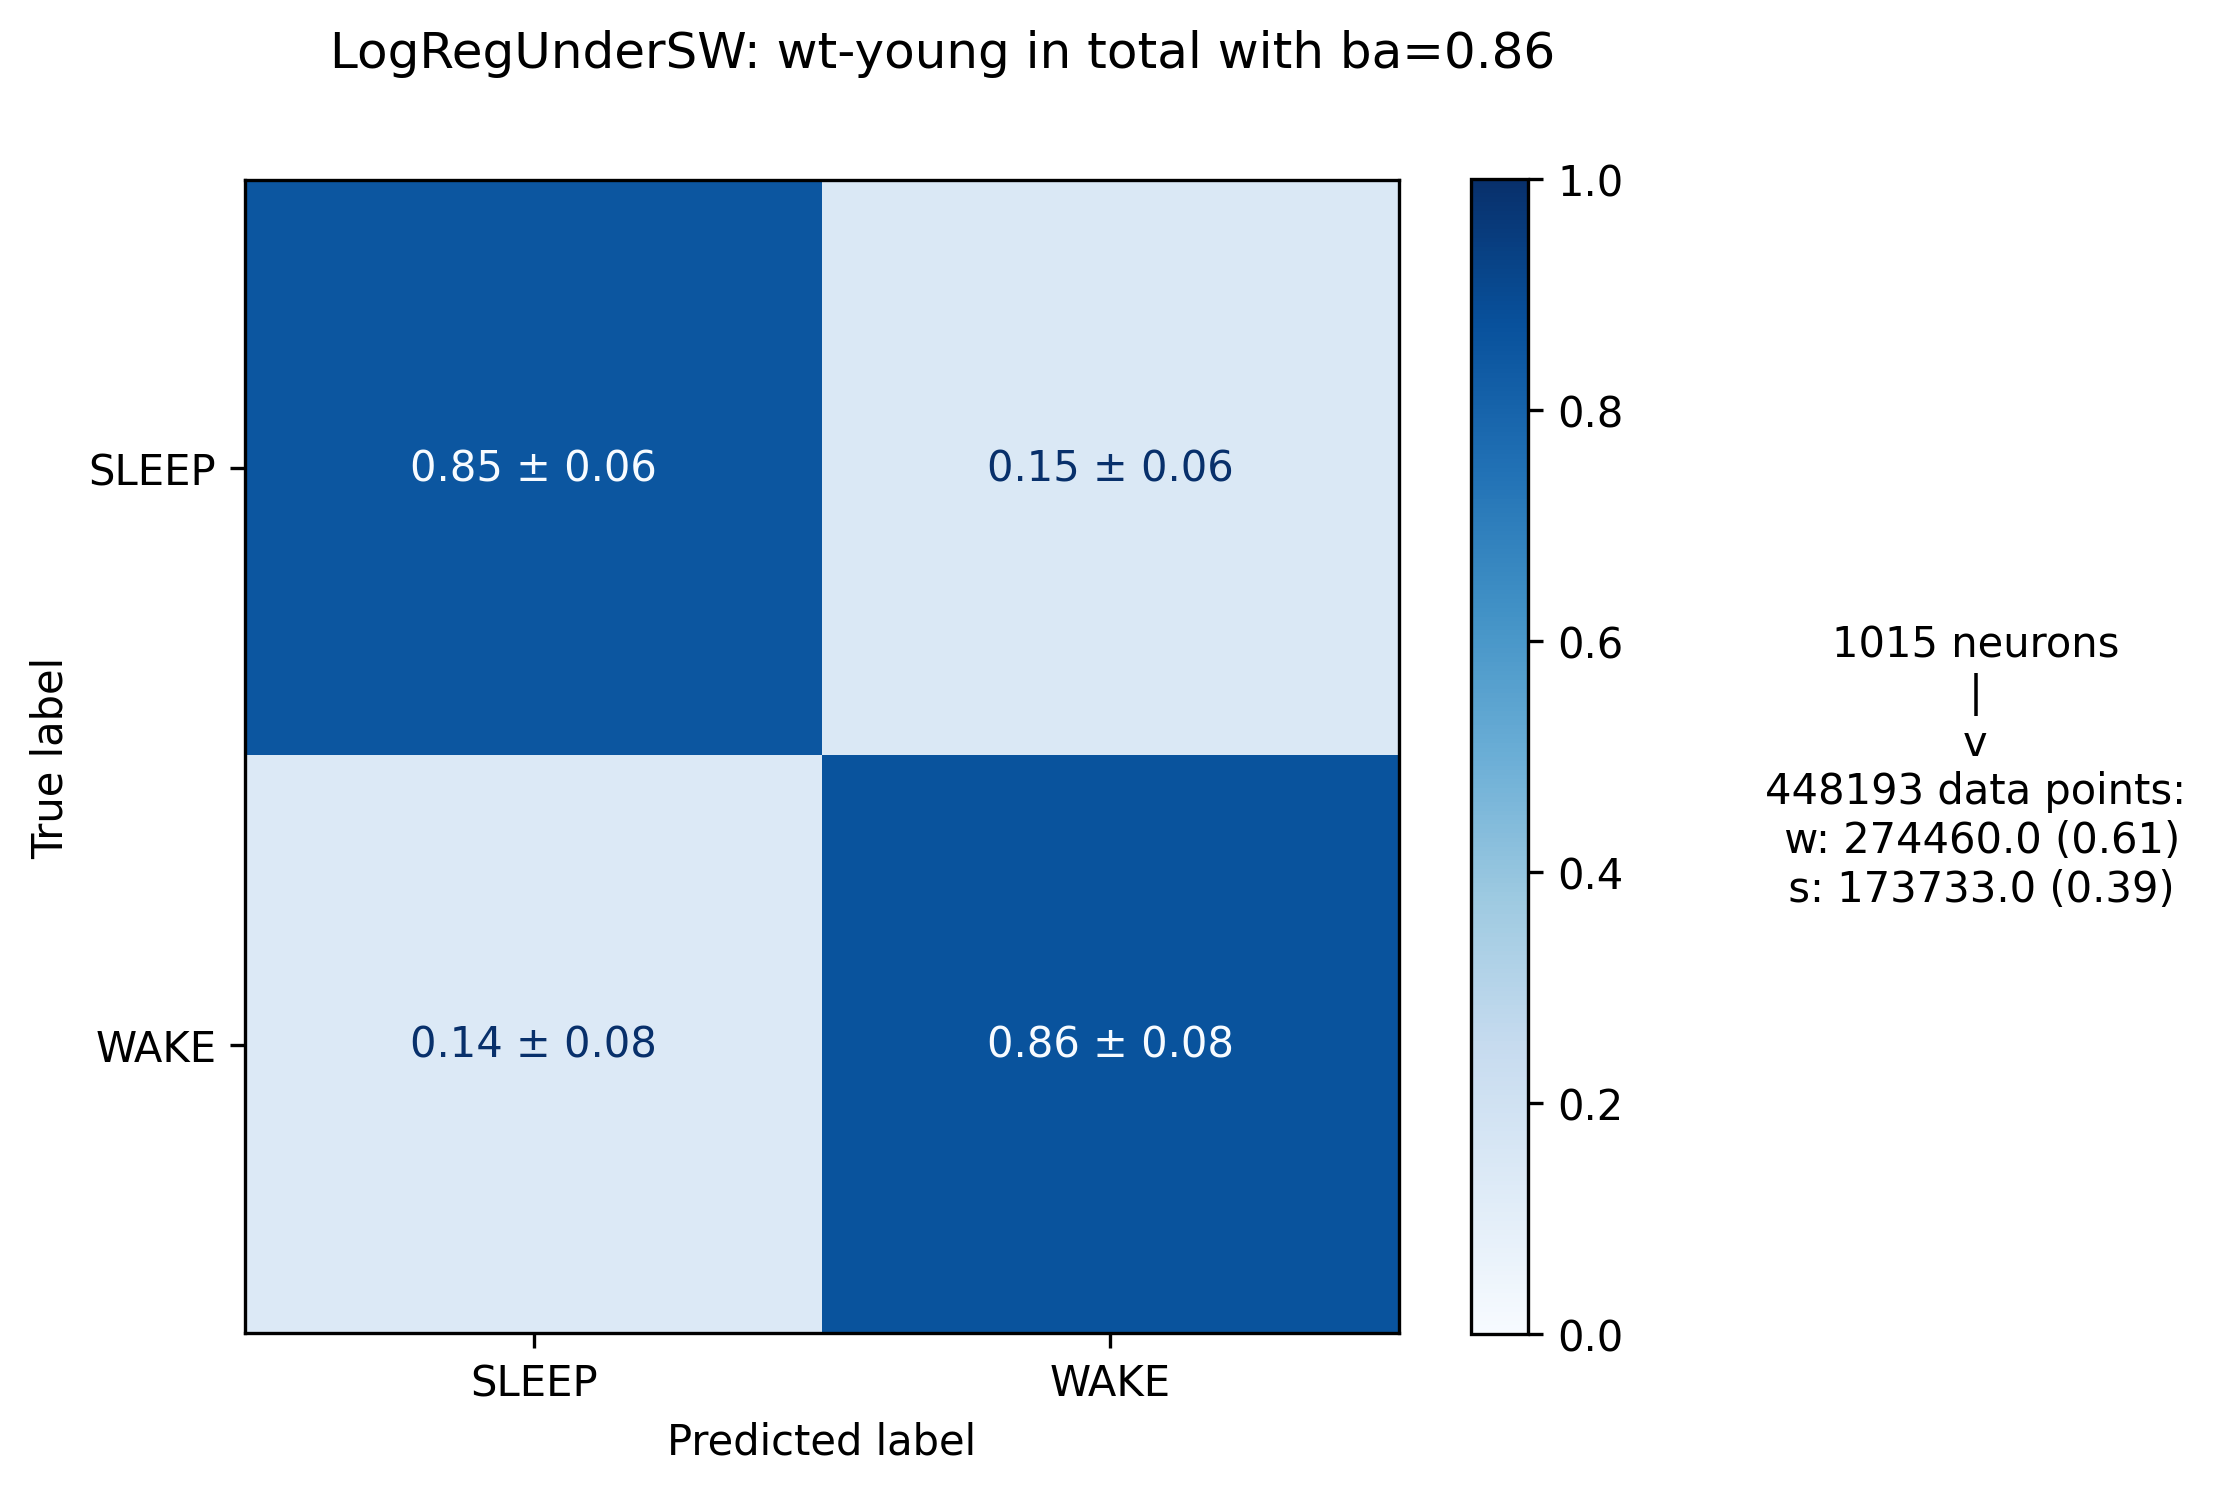

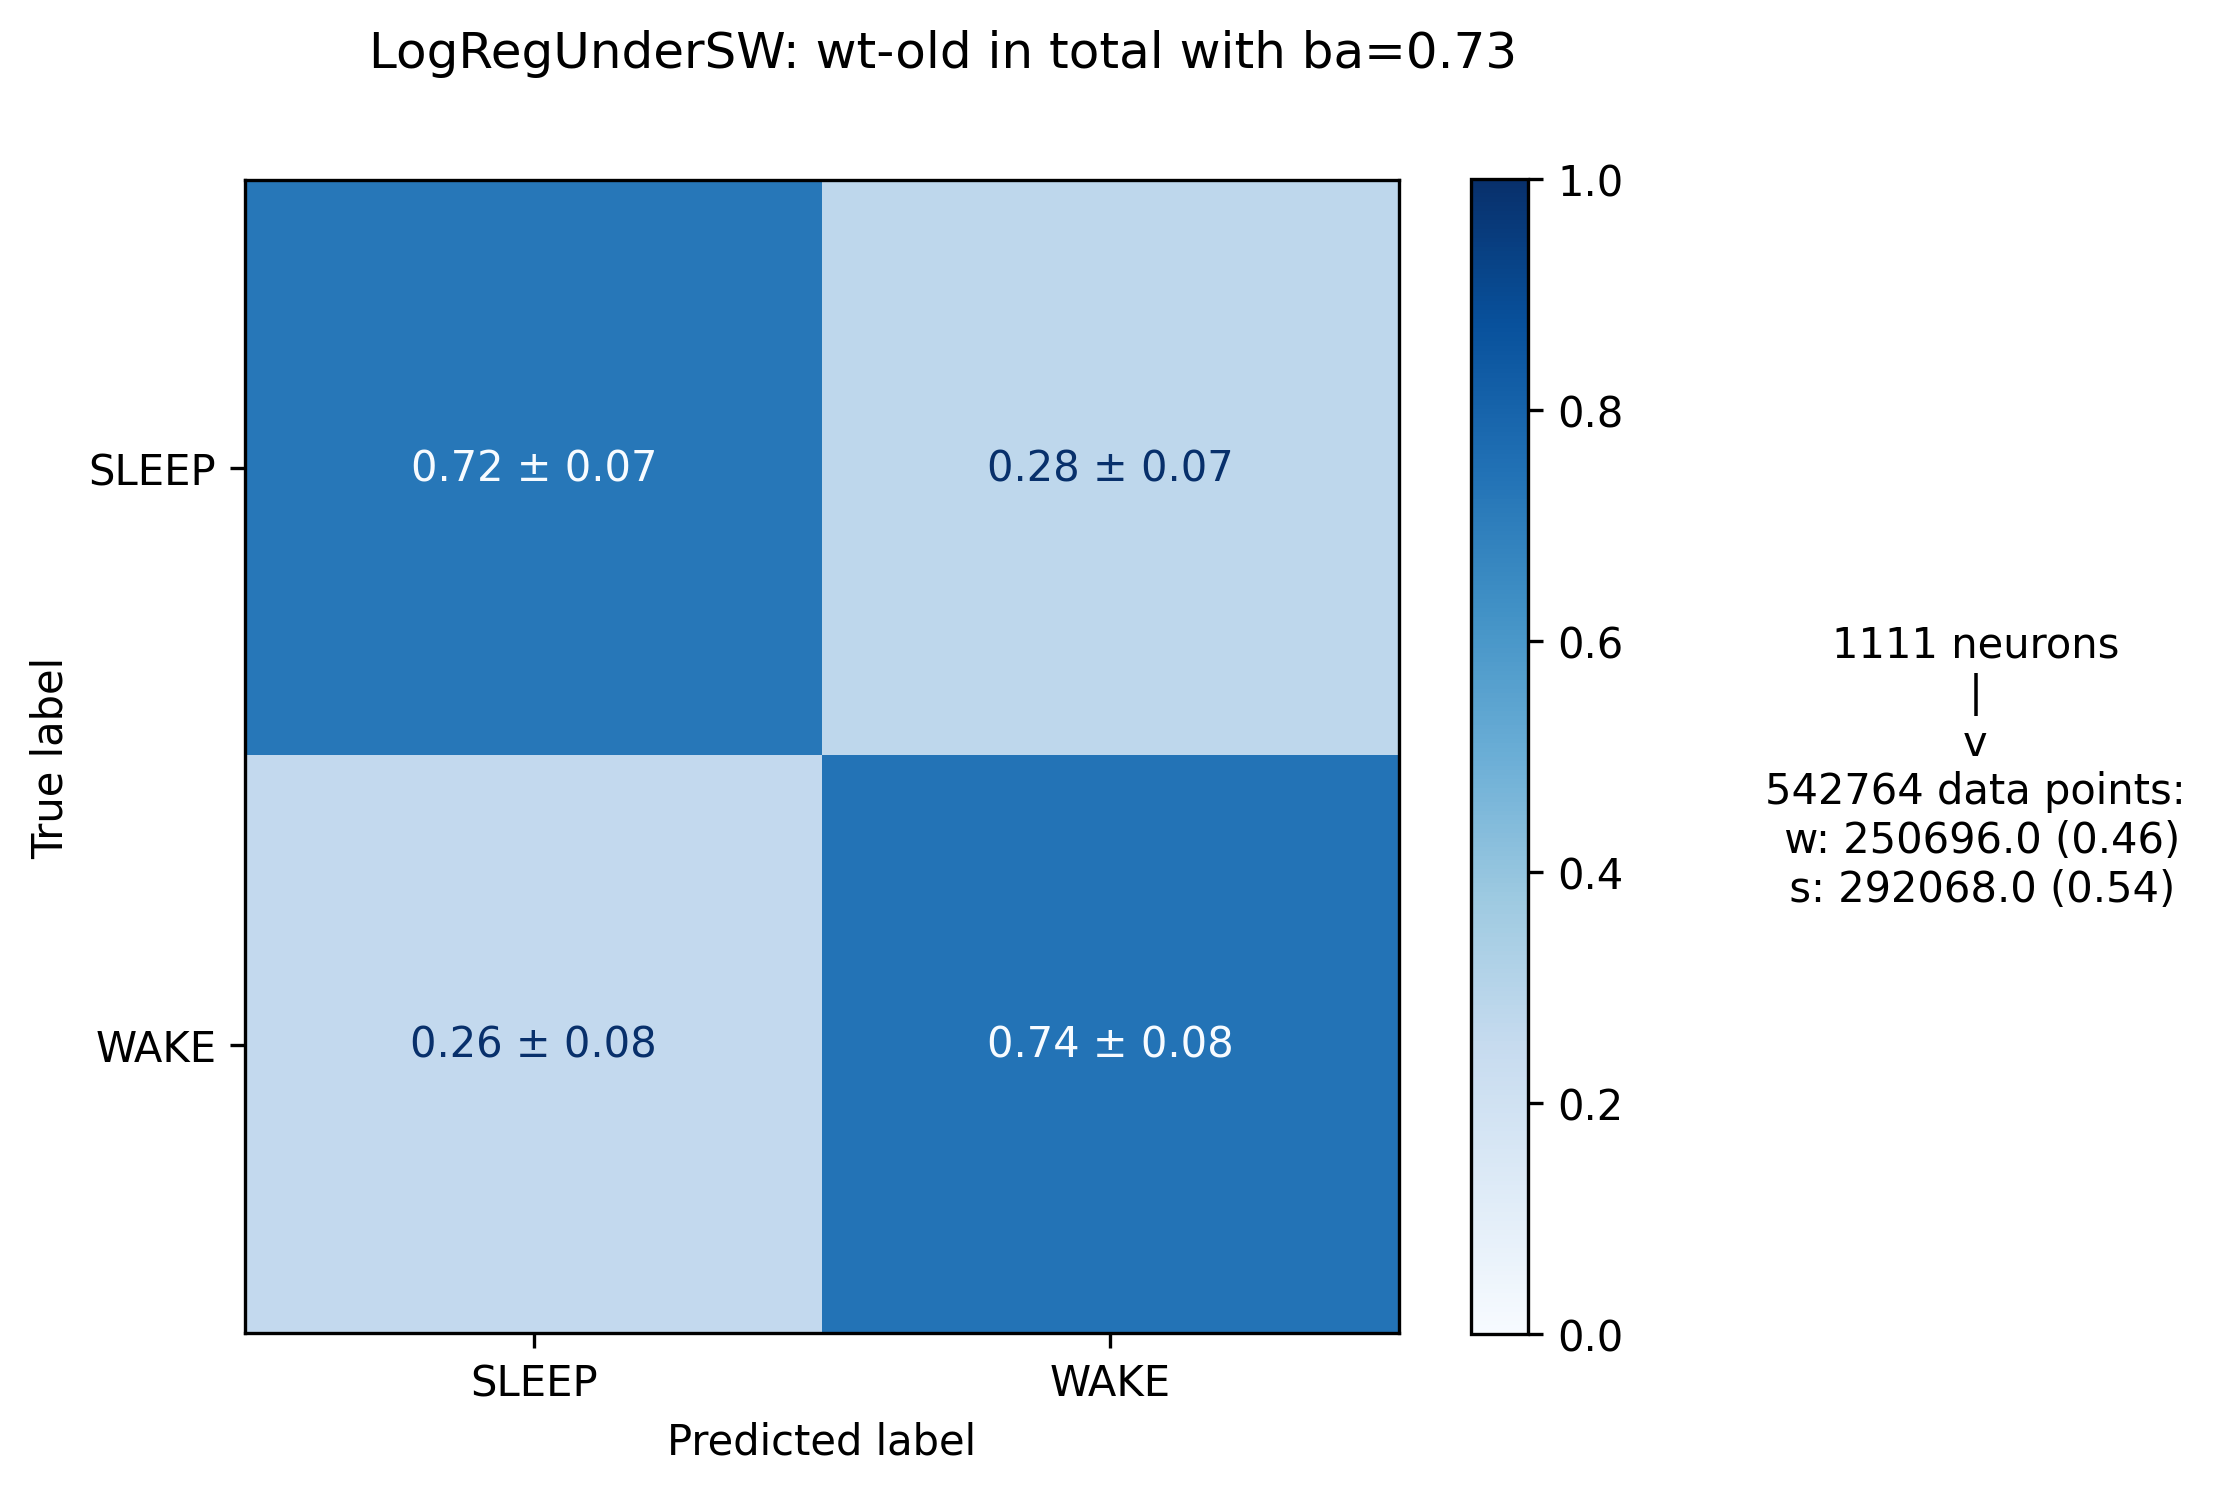

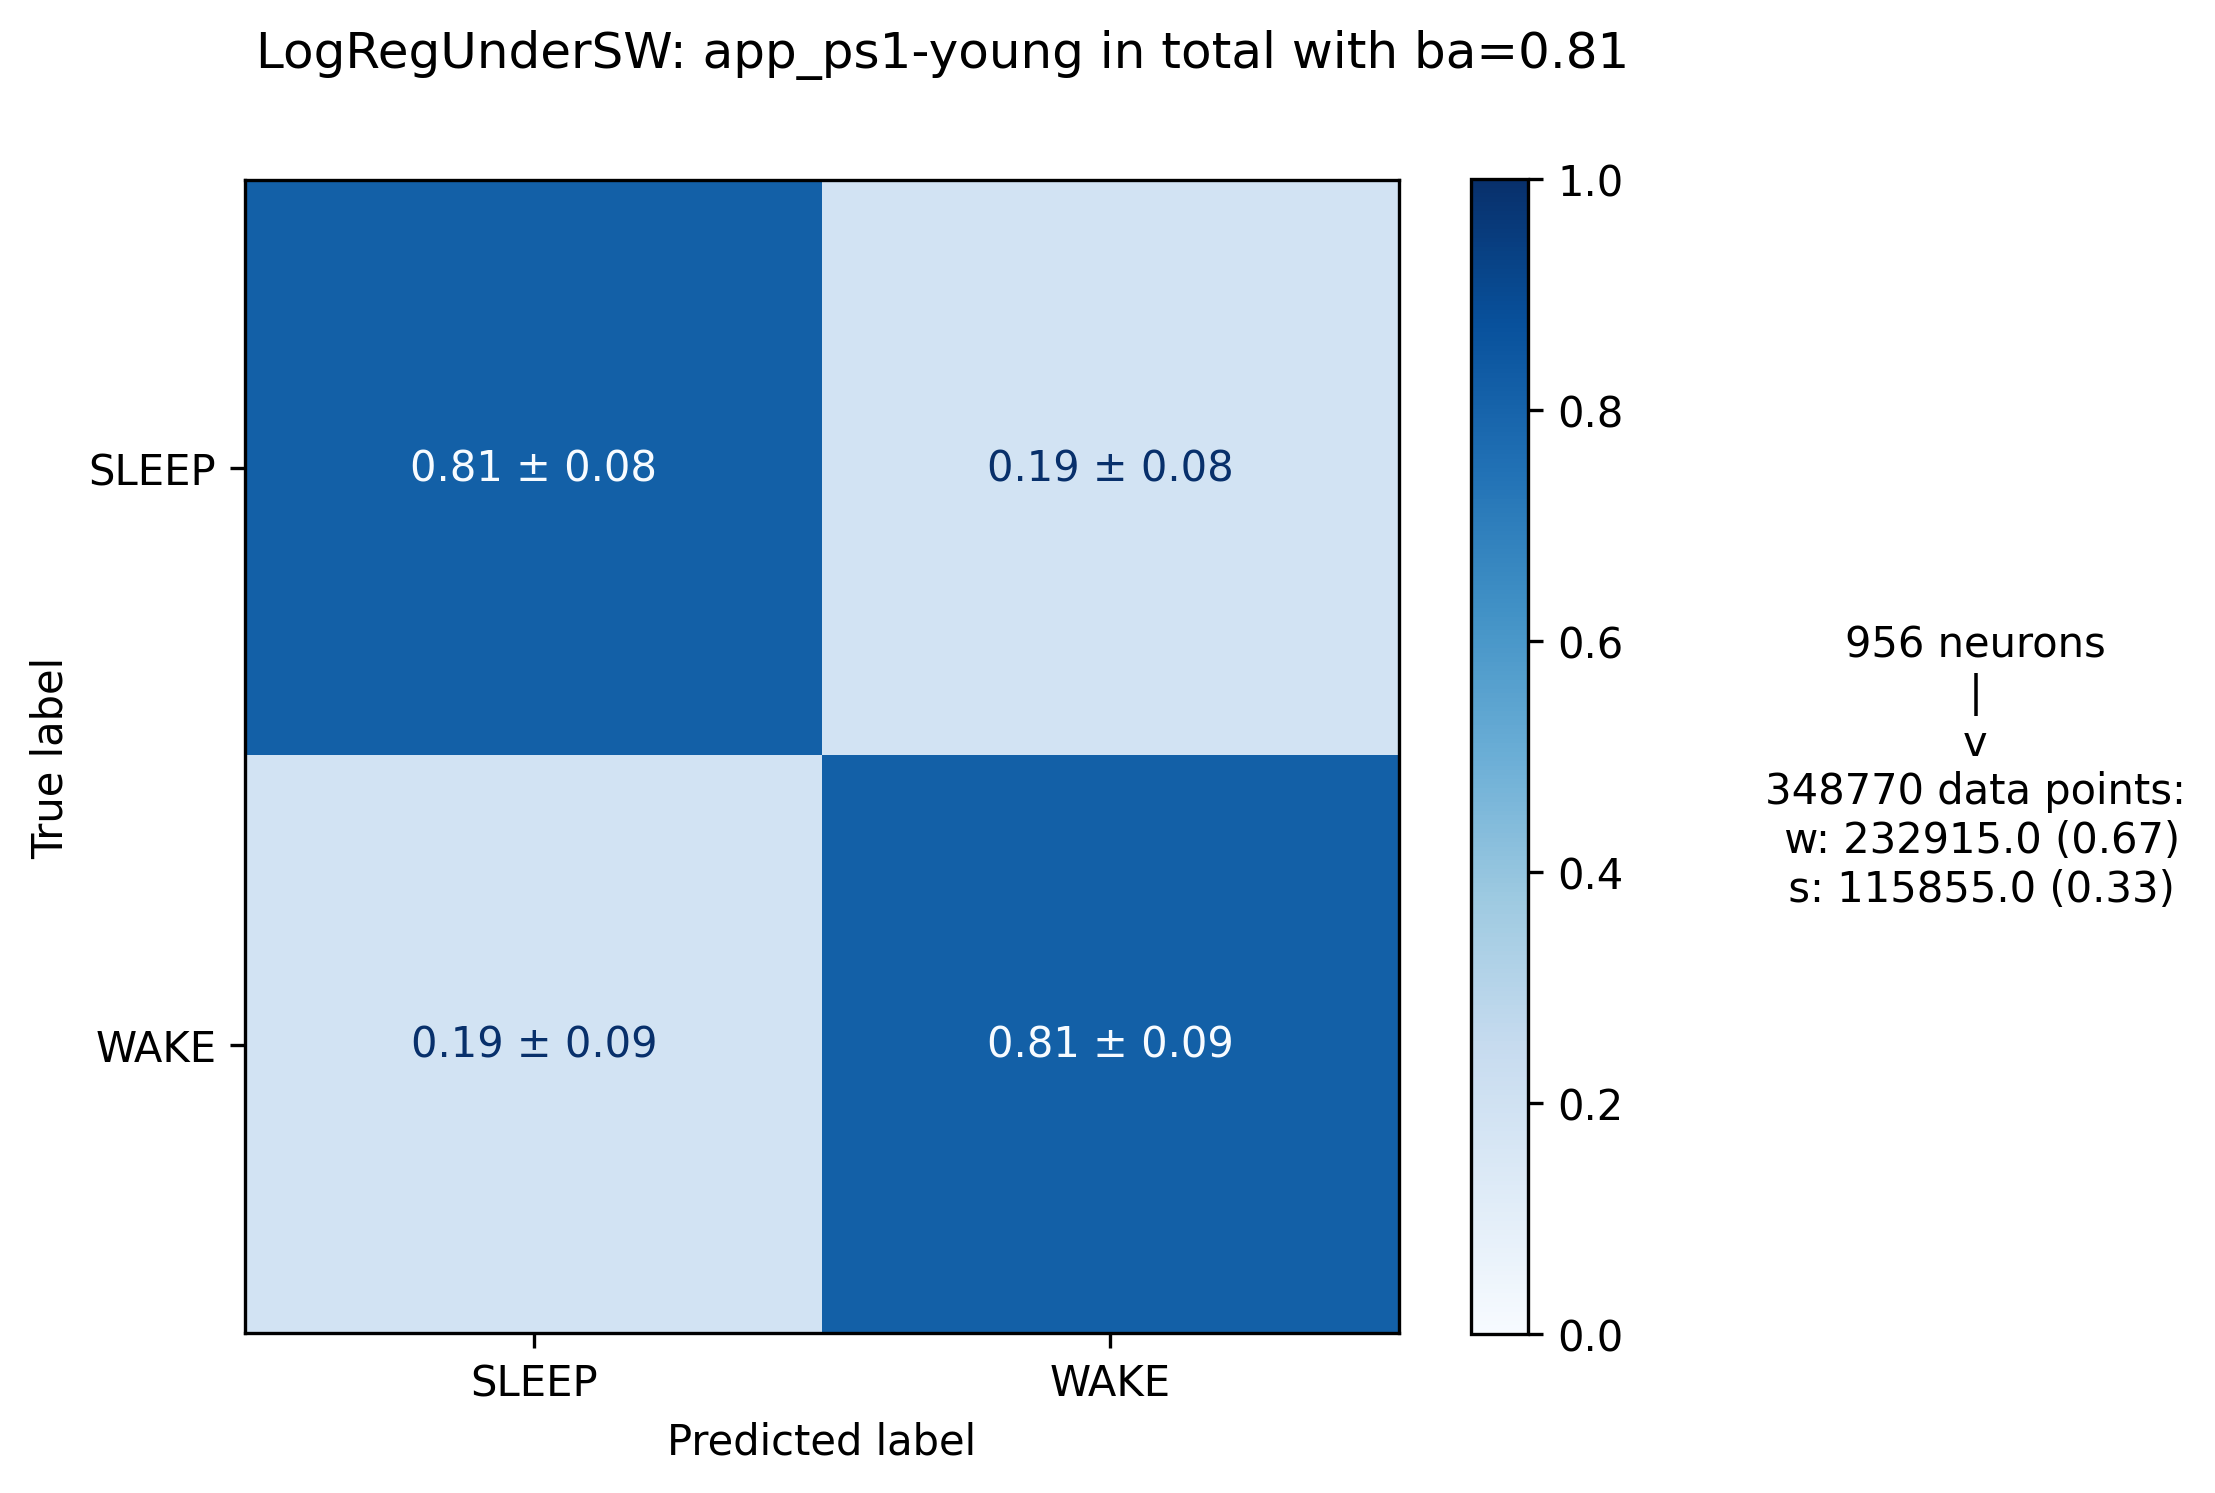

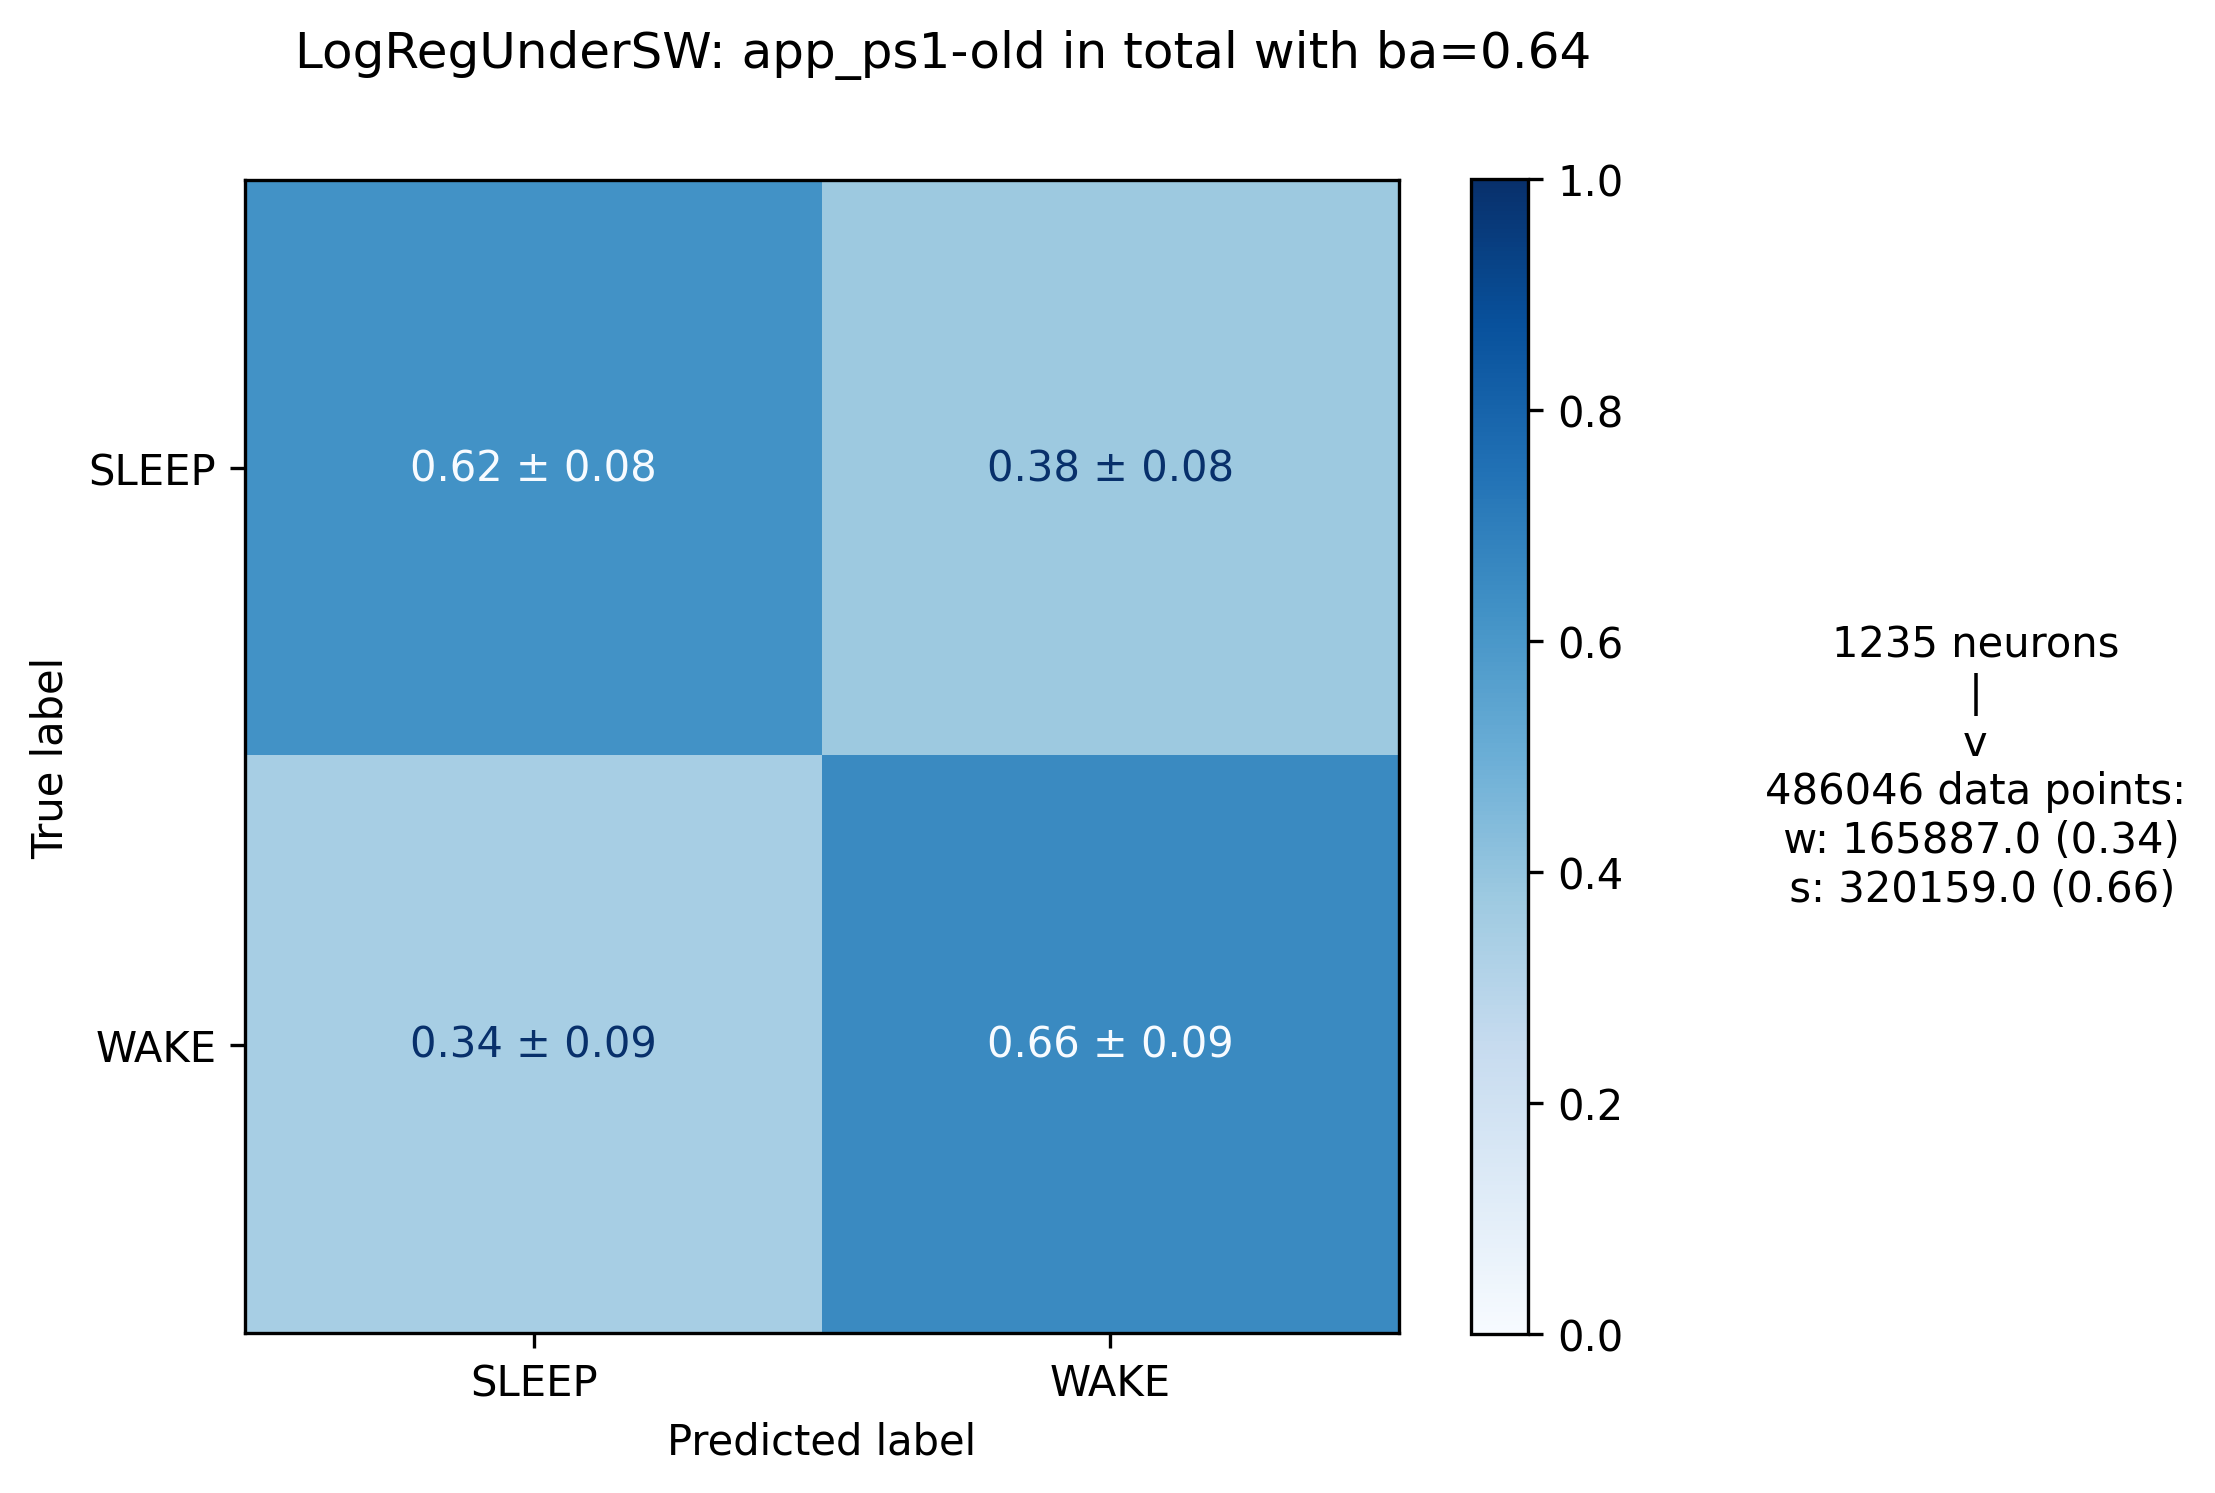

In [7]:
for model_name, matrices in cms.items():
    #Specify norm_size=2 so that the visual works for 2 states
    get_mean_cms_visual(matrices, sw_train_condensed, f"{model_name}SW", subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=True, alt_se=True, norm_size=2, by_geno=True, by_age=True)